In [32]:
import os
os.environ["CUML_LOG_LEVEL"] = "error"

In [33]:
import cudf
import cuml
import cupy as cp
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.model_selection import train_test_split
from cuml.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from cuml.decomposition import PCA
from cuml.cluster import DBSCAN
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
from sklearn.model_selection import ParameterGrid
import numpy as np
import warnings
import kagglehub
warnings.filterwarnings('ignore')

In [34]:
cuml.set_global_output_type('cupy')

In [5]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [6]:
def print_confusion_matrix(cm, title):
    print(f"{title}:")
    print("         Predicted")
    print("         Not Fraud  Fraud")
    print("Actual")
    print(f"Not Fraud  {cm[0,0]:6d}  {cm[0,1]:6d}")
    print(f"Fraud      {cm[1,0]:6d}  {cm[1,1]:6d}")

In [9]:
path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/banksim1


In [10]:
data = cudf.read_csv(path + '/bs140513_032310.csv')

In [11]:
data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
data['customer'] = data['customer'].str[1:-1]
data['age'] = data['age'].str[1:-1]
data['gender'] = data['gender'].str[1:-1]
data['merchant'] = data['merchant'].str[1:-1]
data['category'] = data['category'].str.replace('es_', '')
data = data[data['gender'] != 'U']
data['age'] = data['age'].replace('U', '7')
data['age'] = data['age'].astype('float32')

In [12]:
data['amount'] = data['amount'].astype('float32')
data['amount_thresh'] = cudf.Series('>3000', index=data.index)
data.loc[data['amount'] <= 500, 'amount_thresh'] = '0-500'
data.loc[(data['amount'] > 500) & (data['amount'] <= 1000), 'amount_thresh'] = '500-1000'
data.loc[(data['amount'] > 1000) & (data['amount'] <= 1500), 'amount_thresh'] = '1000-1500'
data.loc[(data['amount'] > 1500) & (data['amount'] <= 2000), 'amount_thresh'] = '1500-2000'
data.loc[(data['amount'] > 2000) & (data['amount'] <= 2500), 'amount_thresh'] = '2000-2500'
data.loc[(data['amount'] > 2500) & (data['amount'] <= 3000), 'amount_thresh'] = '2500-3000'

In [13]:
customer = data.groupby('customer').size().reset_index(name='customer_total_trans')
customer['customer_ID'] = cp.arange(1, len(customer) + 1)

merchant = data.groupby('merchant').size().reset_index(name='merchant_total_trans')
merchant['merchant_ID'] = cp.arange(1, len(merchant) + 1)

category = data.groupby('category').size().reset_index(name='category_total_trans')
category['category_ID'] = cp.arange(1, len(category) + 1)

amount_thresh = data.groupby('amount_thresh').size().reset_index(name='amount_thresh_total_trans')
amount_thresh['amount_thresh_ID'] = cp.arange(1, len(amount_thresh) + 1)

In [14]:
data = data.merge(customer, on='customer').merge(merchant, on='merchant')
data = data.drop(['customer', 'merchant'], axis=1)
data = data.merge(category, on='category').merge(amount_thresh, on='amount_thresh')
data['category'] = data['category_ID']
data['amount_thresh'] = data['amount_thresh_ID']
data = data.drop(['category_ID', 'amount_thresh_ID'], axis=1)

age = data.groupby('age').size().reset_index(name='age_total_trans')
gender = data.groupby('gender').size().reset_index(name='gender_total_trans')
data = data.merge(age, on='age').merge(gender, on='gender')

In [15]:
total_freq = len(data)
data['merchant_total_trans'] = (data['merchant_total_trans'] / total_freq * 100).round(5)
data['category_total_trans'] = (data['category_total_trans'] / total_freq * 100).round(5)
data['amount_thresh_total_trans'] = (data['amount_thresh_total_trans'] / total_freq * 100).round(5)
data['age_total_trans'] = (data['age_total_trans'] / total_freq * 100).round(5)
data['gender_total_trans'] = (data['gender_total_trans'] / total_freq * 100).round(5)

data = data.drop('step', axis=1)
data = data[['fraud'] + [col for col in data.columns if col != 'fraud']]

In [16]:
ohe = OneHotEncoder(sparse=False, handle_unknown='ignore')
ohe_cols = ['age', 'gender', 'category', 'amount_thresh']
ohe_data = ohe.fit_transform(data[ohe_cols])
ohe_feature_names = ohe.get_feature_names(ohe_cols)
ohe_data = cudf.DataFrame(ohe_data, columns=ohe_feature_names)
data = cudf.concat([data.drop(ohe_cols, axis=1), ohe_data], axis=1)

In [17]:
le = LabelEncoder()
data['fraud'] = le.fit_transform(data['fraud'])

print("Data dimensions:", data.shape)

Data dimensions: (594128, 43)


In [18]:
pca_cols = ['age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
            'gender_E', 'gender_F', 'gender_M',
            'category_1', 'category_2', 'category_3', 'category_4', 'category_5', 'category_6', 'category_7',
            'category_8', 'category_9', 'category_10', 'category_11', 'category_12', 'category_13', 'category_14',
            'amount', 'amount_thresh_1', 'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
            'amount_thresh_6', 'amount_thresh_7']
scaler = StandardScaler()
scaled_data_big = scaler.fit_transform(data[pca_cols])
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data_big)
pca_df = cudf.DataFrame(pca_data, columns=['PC1', 'PC2'])
pca_df['fraud'] = data['fraud']

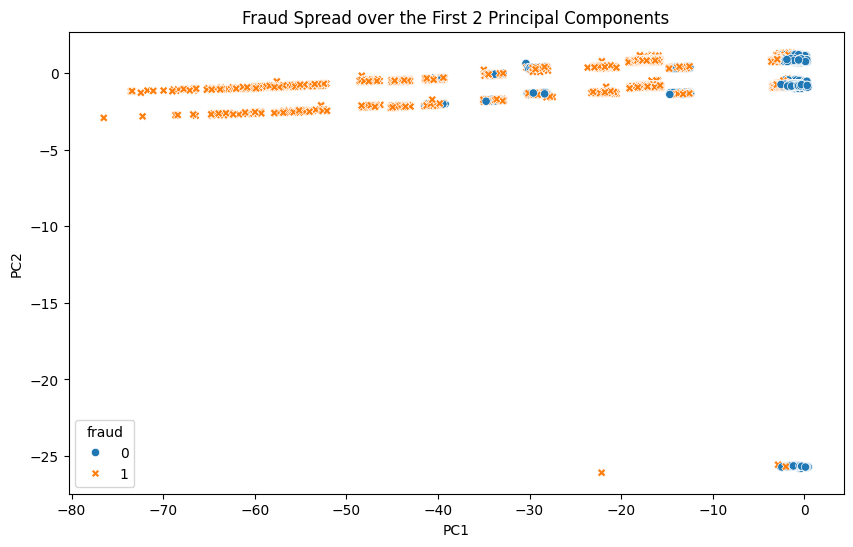

Explained variance ratio: [0.09856101 0.06097504]


In [19]:
pca_df_np = pca_df.to_pandas()
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', data=pca_df_np)
plt.title('Fraud Spread over the First 2 Principal Components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

print("Explained variance ratio:", cp.asnumpy(pca.explained_variance_ratio_))

In [20]:
X = data.drop('fraud', axis=1)
y = data['fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

In [21]:
sample_indices = cp.random.choice(X_train.shape[0], size=min(50000, X_train.shape[0]), replace=False)
X_sample = X_train.iloc[sample_indices]
y_sample = y_train.iloc[sample_indices]

In [22]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

In [23]:
param_grid = {
    'eps': [1.6, 1.65, 1.7, 1.75, 1.8],  # Test near best-performing eps
    'min_samples': [2, 3, 4],             # Test adjacent min_samples
    'fraud_threshold': [0.05, 0.10]       # Test lower thresholds
}

In [24]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [25]:
for params in ParameterGrid(param_grid):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(X_scaled)

    if len(cp.unique(labels)) > 1:
        temp_data = cudf.DataFrame({
            'cluster': labels,
            'true_label': y_sample
        })

        cluster_mapping = {}
        for cluster in cp.unique(labels).get():
            if cluster != -1:
                mask = temp_data['cluster'] == cluster
                fraud_ratio = temp_data[mask]['true_label'].mean()
                cluster_mapping[cluster] = 1 if fraud_ratio > params['fraud_threshold'] else 0

        temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)

        y_true = y_sample.to_numpy()
        y_pred = temp_data['predicted'].to_numpy()

        cm = confusion_matrix(y_true, y_pred)
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred)
        accuracy = accuracy_score(y_true, y_pred)

        results.append({
            'params': params,
            'f1': f1,
            'recall': recall,
            'precision': precision,
            'accuracy': accuracy,
            'confusion_matrix': cm
        })

        print(f"eps={params['eps']:.2f}, min_samples={params['min_samples']}, threshold={params['fraud_threshold']:.0%}")
        print(f"F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}, Accuracy={accuracy:.4f}")

        if f1 > best_f1 or (f1 == best_f1 and recall > best_recall):
            best_f1 = f1
            best_recall = recall
            best_params = params
            best_labels = labels

print("\n=== Best Model ===")
print(f"Parameters: eps={best_params['eps']}, min_samples={best_params['min_samples']}, fraud_threshold={best_params['fraud_threshold']:.0%}")
print(f"F1: {best_f1:.4f}, Recall: {best_recall:.4f}")


[2025-07-09 06:42:35.824] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.60, min_samples=2, threshold=5%
F1=0.3245, Recall=0.4894, Precision=0.2427, Accuracy=0.9750
[2025-07-09 06:42:39.973] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.60, min_samples=3, threshold=5%
F1=0.2712, Recall=0.3931, Precision=0.2070, Accuracy=0.9741
[2025-07-09 06:42:44.978] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.60, min_samples=4, threshold=5%
F1=0.2328, Recall=0.2904, Precision=0.1943, Accuracy=0.9765
[2025-07-09 06:42:49.241] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in b

In [26]:
dbscan_final = DBSCAN(eps=best_params['eps'], min_samples=best_params['min_samples'])
final_labels = dbscan_final.fit_predict(scaler.transform(X_train))

[2025-07-09 06:44:19.836] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 5614 -> 4819. Using the larger integer type might result in better performance


In [27]:
temp_data = cudf.DataFrame({
    'cluster': final_labels,
    'true_label': y_train
})
cluster_mapping = {}
for cluster in cp.unique(final_labels).get():
    if cluster != -1:
        mask = temp_data['cluster'] == cluster
        fraud_ratio = temp_data[mask]['true_label'].mean()
        cluster_mapping[cluster] = 1 if fraud_ratio > best_params['fraud_threshold'] else 0

temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)
y_pred = temp_data['predicted'].to_numpy()

In [28]:
cm = confusion_matrix(y_train.to_numpy(), y_pred)
print_confusion_matrix(cm, "Final Training Confusion Matrix")
print(f"Final Training F1: {f1_score(y_train.to_numpy(), y_pred):.4f}")
print(f"Final Training Recall: {recall_score(y_train.to_numpy(), y_pred):.4f}")
print(f"Final Training Accuracy: {accuracy_score(y_train.to_numpy(), y_pred):.4f}")

Final Training Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  435330    4866
Fraud        1577    3823
Final Training F1: 0.5427
Final Training Recall: 0.7080
Final Training Accuracy: 0.9855


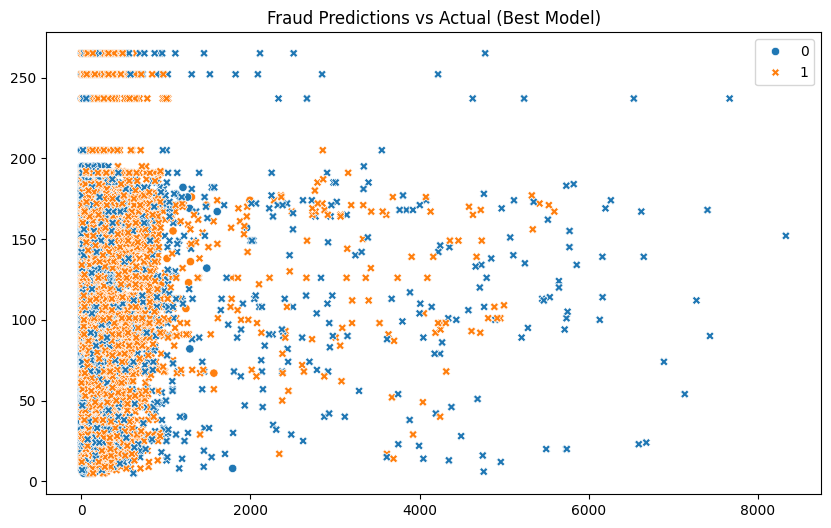

In [31]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_train['amount'].to_numpy(), y=X_train['customer_total_trans'].to_numpy(),
                hue=temp_data['predicted'].to_numpy(), style=y_train.to_numpy())
plt.title("Fraud Predictions vs Actual (Best Model)")
plt.show()

# Trying other parameter sets

In [35]:
param_grid = {
    'eps': [1.8, 1.85, 1.9, 1.95],
    'min_samples': [2],
    'fraud_threshold': [0.10, 0.12, 0.15]
}


In [36]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [37]:
for params in ParameterGrid(param_grid):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(X_scaled)

    if len(cp.unique(labels)) > 1:
        temp_data = cudf.DataFrame({
            'cluster': labels,
            'true_label': y_sample
        })

        cluster_mapping = {}
        for cluster in cp.unique(labels).get():
            if cluster != -1:
                mask = temp_data['cluster'] == cluster
                fraud_ratio = temp_data[mask]['true_label'].mean()
                cluster_mapping[cluster] = 1 if fraud_ratio > params['fraud_threshold'] else 0

        temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)

        y_true = y_sample.to_numpy()
        y_pred = temp_data['predicted'].to_numpy()

        cm = confusion_matrix(y_true, y_pred)
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred)
        accuracy = accuracy_score(y_true, y_pred)

        results.append({
            'params': params,
            'f1': f1,
            'recall': recall,
            'precision': precision,
            'accuracy': accuracy,
            'confusion_matrix': cm
        })

        print(f"eps={params['eps']:.2f}, min_samples={params['min_samples']}, threshold={params['fraud_threshold']:.0%}")
        print(f"F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}, Accuracy={accuracy:.4f}")

        if f1 > best_f1 or (f1 == best_f1 and recall > best_recall):
            best_f1 = f1
            best_recall = recall
            best_params = params
            best_labels = labels

results.sort(key=lambda x: (x['f1'], x['recall']), reverse=True)
print("\n=== Top 3 Models ===")
for i, res in enumerate(results[:3]):
    p = res['params']
    print(f"{i+1}. eps={p['eps']}, min_samples={p['min_samples']}, threshold={p['fraud_threshold']:.0%} -> F1={res['f1']:.4f}, Recall={res['recall']:.4f}, Precision={res['precision']:.4f}, Accuracy={res['accuracy']:.4f}")

print("\n=== Best Model ===")
print(f"Parameters: eps={best_params['eps']}, min_samples={best_params['min_samples']}, fraud_threshold={best_params['fraud_threshold']:.0%}")
print(f"F1: {best_f1:.4f}, Recall: {best_recall:.4f}")


[2025-07-09 06:57:24.362] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.80, min_samples=2, threshold=10%
F1=0.4458, Recall=0.4763, Precision=0.4189, Accuracy=0.9855
[2025-07-09 06:57:28.282] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.80, min_samples=2, threshold=12%
F1=0.4509, Recall=0.4715, Precision=0.4320, Accuracy=0.9859
[2025-07-09 06:57:31.418] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.80, min_samples=2, threshold=15%
F1=0.4613, Recall=0.4568, Precision=0.4659, Accuracy=0.9869
[2025-07-09 06:57:34.576] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result i

# Again Trying other parameter sets

In [40]:
param_grid = {
    'eps': [1.85, 1.86, 1.87, 1.88, 1.89, 1.90],
    'min_samples': [2],
    'fraud_threshold': [0.13, 0.14, 0.15, 0.16, 0.17]
}

In [41]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [42]:
for params in ParameterGrid(param_grid):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(X_scaled)

    if len(cp.unique(labels)) > 1:
        temp_data = cudf.DataFrame({
            'cluster': labels,
            'true_label': y_sample
        })

        cluster_mapping = {}
        for cluster in cp.unique(labels).get():
            if cluster != -1:
                mask = temp_data['cluster'] == cluster
                fraud_ratio = temp_data[mask]['true_label'].mean()
                cluster_mapping[cluster] = 1 if fraud_ratio > params['fraud_threshold'] else 0

        temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)

        y_true = y_sample.to_numpy()
        y_pred = temp_data['predicted'].to_numpy()

        cm = confusion_matrix(y_true, y_pred)
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred)
        accuracy = accuracy_score(y_true, y_pred)

        results.append({
            'params': params,
            'f1': f1,
            'recall': recall,
            'precision': precision,
            'accuracy': accuracy,
            'confusion_matrix': cm
        })

        print(f"eps={params['eps']:.2f}, min_samples={params['min_samples']}, threshold={params['fraud_threshold']:.0%}")
        print(f"F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}, Accuracy={accuracy:.4f}")

        if f1 > best_f1 or (f1 == best_f1 and recall > best_recall):
            best_f1 = f1
            best_recall = recall
            best_params = params
            best_labels = labels

results.sort(key=lambda x: (x['f1'], x['recall']), reverse=True)
print("\n=== Top 3 Models ===")
for i, res in enumerate(results[:3]):
    p = res['params']
    print(f"{i+1}. eps={p['eps']}, min_samples={p['min_samples']}, threshold={p['fraud_threshold']:.0%} -> F1={res['f1']:.4f}, Recall={res['recall']:.4f}, Precision={res['precision']:.4f}, Accuracy={res['accuracy']:.4f}")

print("\n=== Best Model ===")
print(f"Parameters: eps={best_params['eps']}, min_samples={best_params['min_samples']}, fraud_threshold={best_params['fraud_threshold']:.0%}")
print(f"F1: {best_f1:.4f}, Recall: {best_recall:.4f}")


[2025-07-09 07:01:40.967] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.85, min_samples=2, threshold=13%
F1=0.4606, Recall=0.4715, Precision=0.4502, Accuracy=0.9865
[2025-07-09 07:01:44.310] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.85, min_samples=2, threshold=14%
F1=0.4629, Recall=0.4682, Precision=0.4577, Accuracy=0.9867
[2025-07-09 07:01:47.489] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.85, min_samples=2, threshold=15%
F1=0.4660, Recall=0.4633, Precision=0.4686, Accuracy=0.9870
[2025-07-09 07:01:50.658] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result i

# Again Trying other parameter sets

In [43]:
param_grid = {
    'eps': [1.88, 1.89, 1.90, 1.91, 1.92, 1.93],
    'min_samples': [2],
    'fraud_threshold': [0.16, 0.17, 0.18, 0.19, 0.20]
}


In [44]:
best_f1 = -1
best_recall = -1
best_params = None
best_labels = None
results = []

In [45]:
for params in ParameterGrid(param_grid):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(X_scaled)

    if len(cp.unique(labels)) > 1:
        temp_data = cudf.DataFrame({
            'cluster': labels,
            'true_label': y_sample
        })

        cluster_mapping = {}
        for cluster in cp.unique(labels).get():
            if cluster != -1:
                mask = temp_data['cluster'] == cluster
                fraud_ratio = temp_data[mask]['true_label'].mean()
                cluster_mapping[cluster] = 1 if fraud_ratio > params['fraud_threshold'] else 0

        temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)

        y_true = y_sample.to_numpy()
        y_pred = temp_data['predicted'].to_numpy()

        cm = confusion_matrix(y_true, y_pred)
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred)
        accuracy = accuracy_score(y_true, y_pred)

        results.append({
            'params': params,
            'f1': f1,
            'recall': recall,
            'precision': precision,
            'accuracy': accuracy,
            'confusion_matrix': cm
        })

        print(f"eps={params['eps']:.2f}, min_samples={params['min_samples']}, threshold={params['fraud_threshold']:.0%}")
        print(f"F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}, Accuracy={accuracy:.4f}")

        if f1 > best_f1 or (f1 == best_f1 and recall > best_recall):
            best_f1 = f1
            best_recall = recall
            best_params = params
            best_labels = labels


results.sort(key=lambda x: (x['f1'], x['recall']), reverse=True)
print("\n=== Top 3 Models ===")
for i, res in enumerate(results[:3]):
    p = res['params']
    print(f"{i+1}. eps={p['eps']}, min_samples={p['min_samples']}, threshold={p['fraud_threshold']:.0%} -> F1={res['f1']:.4f}, Recall={res['recall']:.4f}, Precision={res['precision']:.4f}, Accuracy={res['accuracy']:.4f}")

print("\n=== Best Model ===")
print(f"Parameters: eps={best_params['eps']}, min_samples={best_params['min_samples']}, fraud_threshold={best_params['fraud_threshold']:.0%}")
print(f"F1: {best_f1:.4f}, Recall: {best_recall:.4f}")


[2025-07-09 07:06:34.868] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.88, min_samples=2, threshold=16%
F1=0.4697, Recall=0.4682, Precision=0.4713, Accuracy=0.9870
[2025-07-09 07:06:38.423] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.88, min_samples=2, threshold=17%
F1=0.4704, Recall=0.4666, Precision=0.4743, Accuracy=0.9871
[2025-07-09 07:06:41.592] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
eps=1.88, min_samples=2, threshold=18%
F1=0.4704, Recall=0.4666, Precision=0.4743, Accuracy=0.9871
[2025-07-09 07:06:45.021] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result i

In [46]:
dbscan_final = DBSCAN(eps=best_params['eps'], min_samples=best_params['min_samples'])
final_labels = dbscan_final.fit_predict(scaler.transform(X_train))

[2025-07-09 07:10:50.845] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 5614 -> 4819. Using the larger integer type might result in better performance


In [47]:
temp_data = cudf.DataFrame({
    'cluster': final_labels,
    'true_label': y_train
})
cluster_mapping = {}
for cluster in cp.unique(final_labels).get():
    if cluster != -1:
        mask = temp_data['cluster'] == cluster
        fraud_ratio = temp_data[mask]['true_label'].mean()
        cluster_mapping[cluster] = 1 if fraud_ratio > best_params['fraud_threshold'] else 0

temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)
y_pred = temp_data['predicted'].to_numpy()

In [48]:
cm = confusion_matrix(y_train.to_numpy(), y_pred)
print_confusion_matrix(cm, "Final Training Confusion Matrix")
print(f"Final Training F1: {f1_score(y_train.to_numpy(), y_pred):.4f}")
print(f"Final Training Recall: {recall_score(y_train.to_numpy(), y_pred):.4f}")
print(f"Final Training Accuracy: {accuracy_score(y_train.to_numpy(), y_pred):.4f}")

Final Training Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  436699    3497
Fraud        1759    3641
Final Training F1: 0.5808
Final Training Recall: 0.6743
Final Training Accuracy: 0.9882


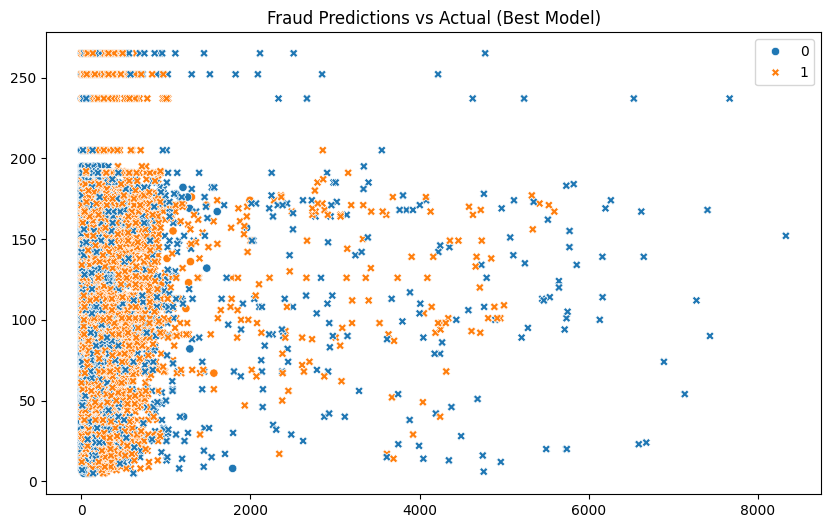

In [49]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_train['amount'].to_numpy(), y=X_train['customer_total_trans'].to_numpy(),
                hue=temp_data['predicted'].to_numpy(), style=y_train.to_numpy())
plt.title("Fraud Predictions vs Actual (Best Model)")
plt.show()

# Trying HDBSCAN

In [50]:
%load_ext cuml.accel
import hdbscan

[2025-07-09 07:19:30.320] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-07-09 07:19:57.845] [CUML] [info] cuML: Installed accelerator for umap.
[2025-07-09 07:19:57.900] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-07-09 07:19:57.900] [CUML] [info] cuML: Successfully initialized accelerator.


In [ ]:
best_f1 = -1
best_params = None
results = []

param_grid = {
    'min_cluster_size': [15, 20, 25, 30],
    'min_samples': [1, 2, 3],
    'fraud_threshold': [0.15, 0.17, 0.18, 0.20]
}

X_np = cp.asnumpy(X_scaled)
y_np = y_sample.to_numpy()

for params in ParameterGrid(param_grid):
    clusterer = hdbscan.HDBSCAN(min_cluster_size=params['min_cluster_size'],
                                 min_samples=params['min_samples'],
                                 prediction_data=True)
    labels = clusterer.fit_predict(X_np)

    if len(np.unique(labels)) > 1:
        temp_data = cudf.DataFrame({
            'cluster': labels,
            'true_label': y_sample
        })

        cluster_mapping = {}
        for cluster_id in np.unique(labels):
            if cluster_id != -1:
                mask = temp_data['cluster'] == cluster_id
                fraud_ratio = temp_data[mask]['true_label'].mean()
                cluster_mapping[cluster_id] = 1 if fraud_ratio > params['fraud_threshold'] else 0

        temp_data['predicted'] = temp_data['cluster'].map(cluster_mapping).fillna(0)
        y_pred = temp_data['predicted'].to_numpy()

        f1 = f1_score(y_np, y_pred)
        recall = recall_score(y_np, y_pred)
        precision = precision_score(y_np, y_pred)
        accuracy = accuracy_score(y_np, y_pred)

        results.append({
            'params': params,
            'f1': f1,
            'recall': recall,
            'precision': precision,
            'accuracy': accuracy
        })

        print(f"min_cluster_size={params['min_cluster_size']}, min_samples={params['min_samples']}, threshold={params['fraud_threshold']:.0%}")
        print(f"F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}, Accuracy={accuracy:.4f}")

        if f1 > best_f1:
            best_f1 = f1
            best_params = params


min_cluster_size=15, min_samples=1, threshold=15%
F1=0.5162, Recall=0.6639, Precision=0.4222, Accuracy=0.9847


In [ ]:
results.sort(key=lambda x: (round(x['f1'], 4), x['recall']), reverse=True)
print("\n=== Top 3 HDBSCAN Models ===")
for i, res in enumerate(results[:3]):
    p = res['params']
    print(f"{i+1}. min_cluster_size={p['min_cluster_size']}, min_samples={p['min_samples']}, threshold={p['fraud_threshold']:.0%} -> F1={res['f1']:.4f}, Recall={res['recall']:.4f}, Precision={res['precision']:.4f}, Accuracy={res['accuracy']:.4f}")